[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-biopython-course/blob/main/notebooks/12_mini_project_target_to_structure.ipynb)

# 12 · Mini Project: From Target to Structure to Selectivity

*Practical Biopython Course · Hamza Hentabli, Ph.D. · ~75 min*

This capstone uses everything from Notebooks 02–11 to answer a question a drug-discovery team
really asks: **"If we bind EGFR's ATP pocket like erlotinib does, which other kinases might we also hit, and
which pocket residues could give us selectivity?"**

Pipeline:

1. **UniProt** → EGFR sequence and kinase-domain boundaries
2. **BLAST** (cached) → closest homologues in Swiss-Prot
3. **Alignment** → kinase domains of a 15-kinase panel (Notebook 07)
4. **PDB 1M17** → erlotinib-contacting residues, renumbered to UniProt
5. **Pocket conservation** → which pocket positions differ between EGFR and each kinase

**Learning objectives.** By the end of this notebook you will be able to:

- chain the course's tools into one reproducible pipeline: UniProt → sequence → BLAST → alignment → PDB → pocket
- make every network step fall back to cached data, and record provenance
- map binding-site residues from a crystal structure onto a multiple sequence alignment
- use pocket conservation to reason about inhibitor selectivity and off-targets

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'biopython', 'requests'], check=True)
    if not os.path.isdir("practical-biopython-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-biopython-course.git"], check=True)
    DATA_DIR = "practical-biopython-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 0. Settings and helpers

In [2]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from Bio import SeqIO, AlignIO, Align
from Bio.Align import substitution_matrices
from Bio.Blast import NCBIXML
from Bio.PDB import MMCIFParser, NeighborSearch, PPBuilder

OFFLINE = os.environ.get("COURSE_OFFLINE") == "1"
TARGET = "P00533"           # UniProt accession of EGFR
PDB_ID = "1M17"             # EGFR kinase domain + erlotinib
LIGAND = "AQ4"              # erlotinib's ligand code in the PDB
CUTOFF = 4.0                # Å, contact distance for "pocket" residues
os.makedirs("output", exist_ok=True)
provenance = {}

def fetch_or_cache(url, cache_path, as_json=False):
    """GET a URL (unless offline) and fall back to a cached file."""
    if not OFFLINE:
        try:
            r = requests.get(url, timeout=30)
            r.raise_for_status()
            provenance[url] = "live"
            return r.json() if as_json else r.text
        except requests.RequestException as err:
            print("network problem:", err)
    provenance[url] = f"cache: {os.path.relpath(cache_path, DATA_DIR)}"
    with open(cache_path) as fh:
        return json.load(fh) if as_json else fh.read()

## 1. UniProt: sequence and kinase domain

In [3]:
from io import StringIO

fasta = fetch_or_cache(f"https://rest.uniprot.org/uniprotkb/{TARGET}.fasta",
                       f"{DATA_DIR}/sequences/P00533_EGFR_human.fasta")
target = SeqIO.read(StringIO(fasta), "fasta")
entry = fetch_or_cache(f"https://rest.uniprot.org/uniprotkb/{TARGET}.json",
                       f"{DATA_DIR}/sequences/P00533_uniprot_features.json", as_json=True)
kd = next(f for f in entry["features"] if f["type"] == "Domain" and f.get("description") == "Protein kinase")
kd_start, kd_end = kd["location"]["start"]["value"], kd["location"]["end"]["value"]
kd_seq = target.seq[kd_start - 1: kd_end]
print(target.description)
print(f"kinase domain {kd_start}-{kd_end} ({len(kd_seq)} aa)")
print("UniProt binding-site annotations:",
      [(f["location"]["start"]["value"], f["location"]["end"]["value"]) for f in entry["features"] if f["type"] == "Binding site"])

sp|P00533|EGFR_HUMAN Epidermal growth factor receptor OS=Homo sapiens OX=9606 GN=EGFR PE=1 SV=2
kinase domain 712-979 (268 aa)
UniProt binding-site annotations: [(718, 726), (745, 745), (790, 791), (855, 855)]


## 2. BLAST: who else has a domain like this?

In [4]:
blast_query = SeqIO.read(f"{DATA_DIR}/blast_cache/EGFR_kinase_domain_query.fasta", "fasta")
print("cached BLAST query == UniProt kinase domain:", blast_query.seq == kd_seq)
with open(f"{DATA_DIR}/blast_cache/EGFR_kinase_blastp_swissprot.xml") as fh:
    blast = NCBIXML.read(fh)
blast_hits = pd.DataFrame([{
    "accession": a.accession,
    "description": a.hit_def.split(";")[0].replace("RecName: Full=", "").split(" [")[0][:40],
    "organism": a.hit_def.rsplit("[", 1)[-1].rstrip("]") if "[" in a.hit_def else "",
    "identity_%": round(100 * a.hsps[0].identities / a.hsps[0].align_length, 1), "evalue": a.hsps[0].expect}
    for a in blast.alignments])
human_hits = blast_hits[blast_hits["organism"] == "Homo sapiens"]
print(len(blast_hits), "Swiss-Prot hits;", len(human_hits), "from human")
human_hits.head(10)

cached BLAST query == UniProt kinase domain: True
50 Swiss-Prot hits; 11 from human


,accession,description,organism,identity_%,evalue
1,P00533,Epidermal growth factor receptor,Homo sapiens,100.0,0.000000e+00
11,P04626,Receptor tyrosine-protein kinase erbB-2,Homo sapiens,81.3,1.181320e-155
13,Q15303,Receptor tyrosine-protein kinase erbB-4,Homo sapiens,79.1,8.835890e-153
20,P21860,Receptor tyrosine-protein kinase erbB-3,Homo sapiens,59.3,1.601830e-108
26,Q07912,Activated CDC42 kinase 1,Homo sapiens,39.7,1.606170e-58
27,P43405,Tyrosine-protein kinase SYK,Homo sapiens,41.7,1.607420e-58
29,P42684,Tyrosine-protein kinase ABL2,Homo sapiens,41.7,2.461180e-58
31,P43403,Tyrosine-protein kinase ZAP-70,Homo sapiens,39.6,4.134350e-58
37,Q05397,Focal adhesion kinase 1,Homo sapiens,38.7,7.827450e-58
47,Q14289,Protein-tyrosine kinase 2-beta,Homo sapiens,37.6,2.411780e-57


The closest human homologues are the other ErbB receptors. To look beyond the family, our panel
(Notebooks 06–07) adds clinically important kinases from other branches: ABL1, SRC, BTK, BRAF, VEGFR2,
MET, ALK, and CDK2.

In [5]:
panel = pd.read_csv(f"{DATA_DIR}/sequences/kinase_panel.csv")
in_blast = panel["accession"].isin(blast_hits["accession"].str.split(".").str[0])
panel.assign(in_top50_blast=in_blast)[["entry_name", "organism", "in_top50_blast"]]

,entry_name,organism,in_top50_blast
0,EGFR_HUMAN,Homo sapiens,True
1,ERBB2_HUMAN,Homo sapiens,True
2,ERBB3_HUMAN,Homo sapiens,True
3,ERBB4_HUMAN,Homo sapiens,True
4,EGFR_MOUSE,Mus musculus,True
5,EGFR_DROME,Drosophila melanogaster,True
6,LET23_CAEEL,Caenorhabditis elegans,True
7,ABL1_HUMAN,Homo sapiens,False
8,SRC_HUMAN,Homo sapiens,False
9,BRAF_HUMAN,Homo sapiens,False


## 3. The alignment

In [6]:
aln = Align.read(f"{DATA_DIR}/alignments/kinase_domains_famsa.aln", "clustal")
names = [s.id for s in aln.sequences]
arr = np.array(aln, dtype="U")
egfr_row = arr[names.index("EGFR_HUMAN")]
assert "".join(c for c in egfr_row if c != "-") == str(kd_seq), "alignment row must match the UniProt domain"

col_of = {}
pos = kd_start - 1
for j, ch in enumerate(egfr_row):
    if ch != "-":
        pos += 1
        col_of[pos] = j
print(arr.shape, "| EGFR residues mapped to columns:", len(col_of))

(15, 377) | EGFR residues mapped to columns: 268


## 4. The structure: pocket residues in UniProt numbering

In [7]:
from Bio.PDB import PDBList

path = None
if not OFFLINE:
    try:
        path = PDBList(verbose=False).retrieve_pdb_file(PDB_ID, file_format="mmCif", pdir="output/pdb")
        provenance[f"PDB {PDB_ID}"] = "live"
    except Exception as err:
        print("PDB download failed:", err)
if not path or not os.path.exists(path):
    path = f"{DATA_DIR}/structures/{PDB_ID}.cif"
    provenance[f"PDB {PDB_ID}"] = "cache: structures/1M17.cif"
structure = MMCIFParser(QUIET=True).get_structure(PDB_ID, path)
chain = structure[0]["A"]

# renumber: align the first modelled peptide to UniProt
pp = PPBuilder().build_peptides(chain)[0]
al = Align.PairwiseAligner(mode="local", substitution_matrix=substitution_matrices.load("BLOSUM62"),
                           open_gap_score=-10, extend_gap_score=-0.5)
a = al.align(target.seq, pp.get_sequence())[0]
offset = (a.aligned[0][0][0] + 1) - pp[0].id[1]
print("PDB -> UniProt numbering offset:", f"{offset:+d}")

ligand = next(r for r in chain if r.get_resname() == LIGAND)
ns = NeighborSearch(list(structure[0].get_atoms()))
pocket = {}
for la in ligand:
    for atom in ns.search(la.coord, CUTOFF):
        r = atom.get_parent()
        if r.id[0] == " ":
            u = r.id[1] + offset
            pocket[u] = min(pocket.get(u, 99), float(la - atom))
pocket = dict(sorted(pocket.items()))
print(len(pocket), "pocket residues (UniProt numbering):",
      ", ".join(f"{target.seq[u - 1]}{u}" for u in pocket))

PDB -> UniProt numbering offset: +24
15 pocket residues (UniProt numbering): L718, A743, K745, E762, L788, T790, Q791, L792, M793, P794, F795, G796, L844, T854, D855


In [8]:
# sanity check: each structure residue name must match the UniProt residue at the renumbered position
from Bio.SeqUtils import seq1
mismatch = [u for u in pocket if seq1(chain[u - offset].get_resname()) != target.seq[u - 1]]
print("numbering mismatches:", mismatch or "none")

numbering mismatches: none


## 5. Pocket conservation across the kinase panel

In [9]:
labels = [f"{target.seq[u - 1]}{u}" for u in pocket]
pocket_cols = [col_of[u] for u in pocket]
P = arr[:, pocket_cols]                                   # kinases x pocket positions (letters)
same = (P == P[names.index("EGFR_HUMAN")]).astype(int)      # 1 = same residue as EGFR
pocket_res = pd.DataFrame(P, index=names, columns=labels)

summary = pd.DataFrame({
    "pocket_identity_%": (100 * same.mean(axis=1)).round(1),
    "domain_identity_%": [round(100 * np.mean([(x == y) for x, y in zip(row, egfr_row) if x != "-" and y != "-"]), 1)
                          for row in arr],
}, index=names).sort_values("pocket_identity_%", ascending=False)
summary

,pocket_identity_%,domain_identity_%
EGFR_HUMAN,100.0,100.0
ERBB2_HUMAN,93.3,81.3
ERBB4_HUMAN,93.3,79.1
EGFR_DROME,93.3,58.6
EGFR_MOUSE,93.3,98.9
LET23_CAEEL,66.7,44.4
ERBB3_HUMAN,60.0,58.5
ABL1_HUMAN,60.0,40.0
SRC_HUMAN,60.0,35.2
ALK_HUMAN,60.0,32.0


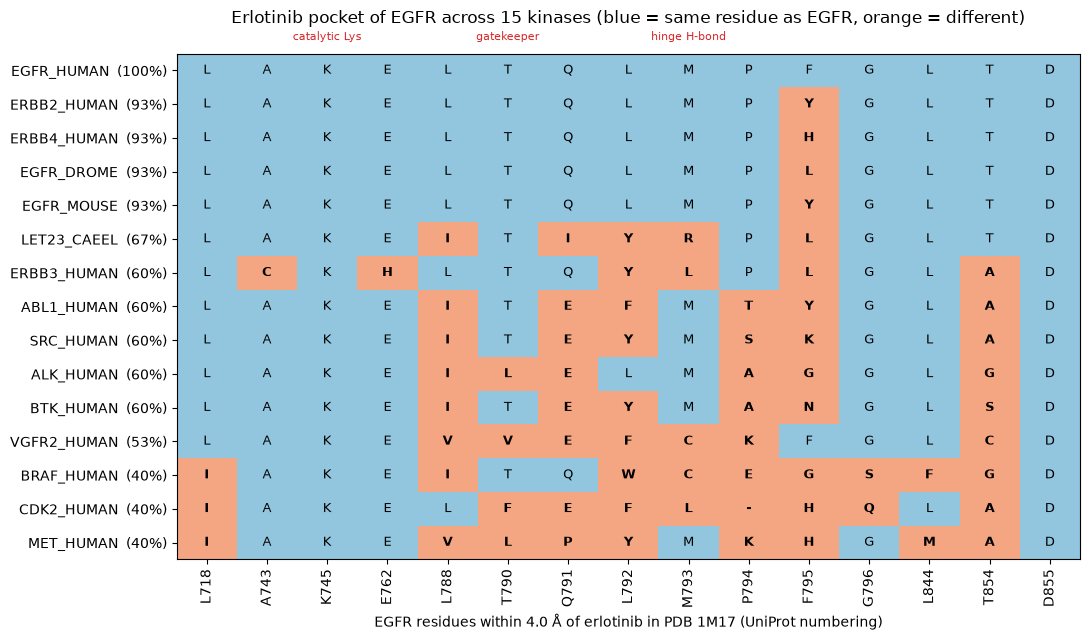

In [10]:
order = summary.index.tolist()
mat = pd.DataFrame(same, index=names, columns=labels).loc[order]
letters = pocket_res.loc[order]

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.imshow(mat.values, cmap=plt.matplotlib.colors.ListedColormap(["#f4a582", "#92c5de"]), aspect="auto")
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, letters.iat[i, j], ha="center", va="center", fontsize=9,
                fontweight="bold" if mat.iat[i, j] == 0 else "normal")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=90)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{n}  ({summary.loc[n, 'pocket_identity_%']:.0f}%)" for n in order])
for lab, note in [("K745", "catalytic Lys"), ("T790", "gatekeeper"), ("M793", "hinge H-bond")]:
    if lab in labels:
        ax.text(labels.index(lab), -0.9, note, ha="center", fontsize=8, color="tab:red")
ax.set_xlabel(f"EGFR residues within {CUTOFF} Å of erlotinib in PDB {PDB_ID} (UniProt numbering)")
ax.set_title("Erlotinib pocket of EGFR across 15 kinases (blue = same residue as EGFR, orange = different)", pad=22)
plt.tight_layout()
plt.savefig("output/pocket_conservation.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the figure**

- Rows are sorted by **pocket identity** to EGFR (shown in brackets). EGFR's closest relatives (ERBB2, ERBB4,
  and the mouse and fly EGFRs) share almost the whole pocket: an erlotinib-like compound will likely hit them too.
- Columns that are blue all the way down (the catalytic **K745**, **E762**, and the DFG **D855**) cannot give selectivity.
- Columns that vary, such as the **gatekeeper T790** and the hinge-region residues **L792–F795**, are where
  medicinal chemists look for selectivity, and where resistance mutations such as T790M arise.
- Pocket identity and whole-domain identity do not always agree (see the table above): the pocket is what
  the drug sees.

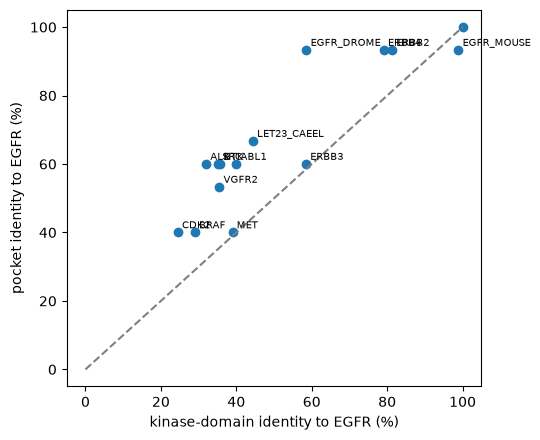

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(summary["domain_identity_%"], summary["pocket_identity_%"])
for n, r in summary.iterrows():
    if n != "EGFR_HUMAN":
        ax.annotate(n.replace("_HUMAN", ""), (r["domain_identity_%"], r["pocket_identity_%"]), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
ax.plot([0, 100], [0, 100], ls="--", color="gray")
ax.set_xlabel("kinase-domain identity to EGFR (%)"); ax.set_ylabel("pocket identity to EGFR (%)")
plt.tight_layout(); plt.show()

## 6. Save results and provenance

In [12]:
summary.to_csv("output/pocket_vs_domain_identity.csv")
pocket_res.to_csv("output/pocket_residues_by_kinase.csv")
with open(f"{DATA_DIR}/provenance.json") as fh:
    cached = json.load(fh)
report = {"target": TARGET, "pdb": PDB_ID, "ligand": LIGAND, "cutoff_A": CUTOFF,
          "pdb_to_uniprot_offset": int(offset), "pocket_residues": labels,
          "sources_used_this_run": provenance, "cache_retrieval_dates": {k: v["retrieved"] for k, v in cached.items()}}
with open("output/pipeline_report.json", "w") as fh:
    json.dump(report, fh, indent=2)
print(json.dumps(report, indent=2))

{
  "target": "P00533",
  "pdb": "1M17",
  "ligand": "AQ4",
  "cutoff_A": 4.0,
  "pdb_to_uniprot_offset": 24,
  "pocket_residues": [
    "L718",
    "A743",
    "K745",
    "E762",
    "L788",
    "T790",
    "Q791",
    "L792",
    "M793",
    "P794",
    "F795",
    "G796",
    "L844",
    "T854",
    "D855"
  ],
  "sources_used_this_run": {
    "https://rest.uniprot.org/uniprotkb/P00533.fasta": "live",
    "https://rest.uniprot.org/uniprotkb/P00533.json": "live",
    "PDB 1M17": "live"
  },
  "cache_retrieval_dates": {
    "uniprot": "2026-11-24",
    "entrez": "2026-11-24",
    "pdb": "2026-11-24",
    "msa": "2026-11-24",
    "blast": "2026-11-24"
  }
}


## Extend the project

The exercises turn the pipeline into a tool you can reuse for your own target.

### ✏️ Exercise 1

Which **non-ErbB** kinases have the highest pocket identity to EGFR? For each of them, list the pocket
positions where it differs from EGFR.

In [13]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
non_erbb = summary.drop(["EGFR_HUMAN", "EGFR_MOUSE", "ERBB2_HUMAN", "ERBB3_HUMAN", "ERBB4_HUMAN",
                         "EGFR_DROME", "LET23_CAEEL"])
top = non_erbb[non_erbb["pocket_identity_%"] == non_erbb["pocket_identity_%"].max()]
for kinase in top.index:
    diff = [f"{lab}{pocket_res.loc[kinase, lab]}" for lab in labels
            if pocket_res.loc[kinase, lab] != pocket_res.loc["EGFR_HUMAN", lab]]
    print(f"{kinase:<11} pocket {top.loc[kinase, 'pocket_identity_%']}% | differs at: {', '.join(diff)}")
```

</details>

### ✏️ Exercise 2

Change `CUTOFF` to 5.0 Å, rerun the pocket and conservation cells (sections 4–5), and report how many pocket
residues you get. Does the ranking of kinases change?

*Hint:* Larger cut-offs include second-shell residues that do not touch the ligand.

In [14]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
# set CUTOFF = 5.0 in section 0, then "Run all" (or re-run sections 4 and 5)
print("current cutoff:", CUTOFF, "| pocket size:", len(pocket))
```

</details>

### ✏️ Exercise 3

Add the **C797** column even though it is not within 4 Å of erlotinib (it is the covalent anchor of osimertinib).
Which kinases share it?

In [15]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
c797 = pd.Series(arr[:, col_of[797]], index=names)
print("kinases with Cys at the EGFR C797 position:", c797[c797 == "C"].index.tolist())
```

</details>

## Key takeaways

- A reproducible pipeline is a chain of small, checked steps, each with a cached fallback and recorded provenance.
- **Renumber** structures to UniProt and **assert** that sequences match before combining sources.
- Mapping a crystal-structure pocket onto an alignment turns "sequence similarity" into a concrete selectivity hypothesis.

**Congratulations, you have finished the course!** Continue with the companion
[Practical Cheminformatics Course](https://github.com/hentablihamza/practical-cheminformatics-course) to model the
*ligands* that bind these pockets.